# Customer Churn: Exploratory Data Analysis
Every chart below starts with the business question it answers.
Dashed grey line in the charts = overall churn rate.

In [1]:
import sys
from pathlib import Path

# Make "src" importable whether the notebook runs from the project root or notebooks/
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.data_preprocessing import load_features

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = load_features()
df["status"] = df["churn"].map({0: "Stayed", 1: "Churned"})
OVERALL = 100 * df["churn"].mean()
print(df.shape, f"| overall churn rate: {OVERALL:.2f}%")


def churn_table(data: pd.DataFrame, column: str) -> pd.DataFrame:
    """Customers, churners and churn rate (%) for each value of one column."""
    table = data.groupby(column, observed=True)["churn"].agg(customers="size", churned="sum")
    table["churn_rate_pct"] = (100 * table["churned"] / table["customers"]).round(2)
    return table


def bar_rates(ax, table: pd.DataFrame, title: str) -> None:
    """Bar chart of churn rate per category, with the overall rate as a dashed line."""
    bars = ax.bar(table.index.astype(str), table["churn_rate_pct"])
    ax.bar_label(bars, fmt="%.1f%%", padding=2)
    ax.axhline(OVERALL, ls="--", color="grey", lw=1)
    ax.set_title(title)
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel("")
    ax.set_ylim(0, max(table["churn_rate_pct"].max(), OVERALL) * 1.2)


def save_fig(name: str) -> None:
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

(7043, 26) | overall churn rate: 26.54%


## Q1. What share of our customers churn?

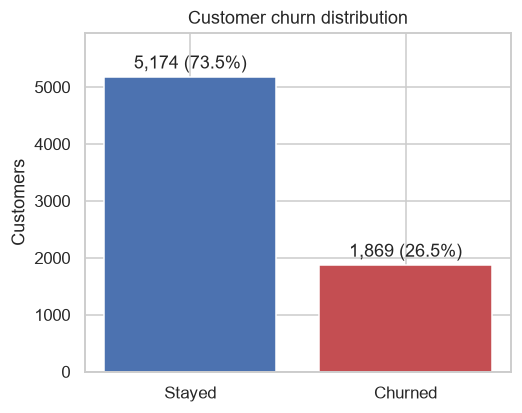

In [2]:
counts = df["status"].value_counts()  # Stayed first, Churned second
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(counts.index, counts.values, color=["#4c72b0", "#c44e52"])
ax.bar_label(bars, labels=[f"{v:,} ({v / len(df):.1%})" for v in counts.values], padding=3)
ax.set_title("Customer churn distribution")
ax.set_ylabel("Customers")
ax.set_ylim(0, counts.max() * 1.15)
save_fig("01_churn_distribution")
plt.show()

## Q2. Which demographic groups churn more?
Gender is included as a check: if it shows no difference, we should not use it in retention rules.

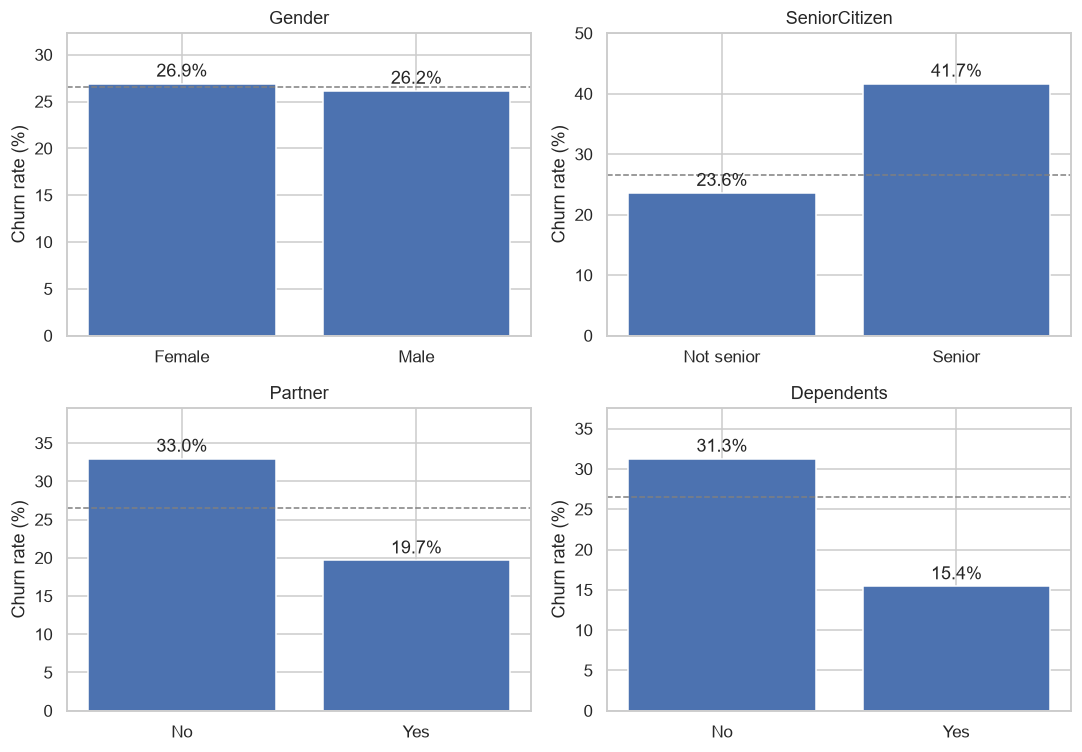

In [3]:
demo = df.assign(
    Gender=df["gender"],
    SeniorCitizen=df["senior_citizen"].map({1: "Senior", 0: "Not senior"}),
    Partner=df["has_partner"].map({1: "Yes", 0: "No"}),
    Dependents=df["has_dependents"].map({1: "Yes", 0: "No"}),
)
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, column in zip(axes.ravel(), ["Gender", "SeniorCitizen", "Partner", "Dependents"]):
    bar_rates(ax, churn_table(demo, column), column)
plt.tight_layout()
save_fig("02_demographics")
plt.show()

## Q3. How much does contract type change churn, and where do the churners sit?
Right chart: if the "Churners" bar is much taller than the "Customers" bar, that group is over-represented among churners.

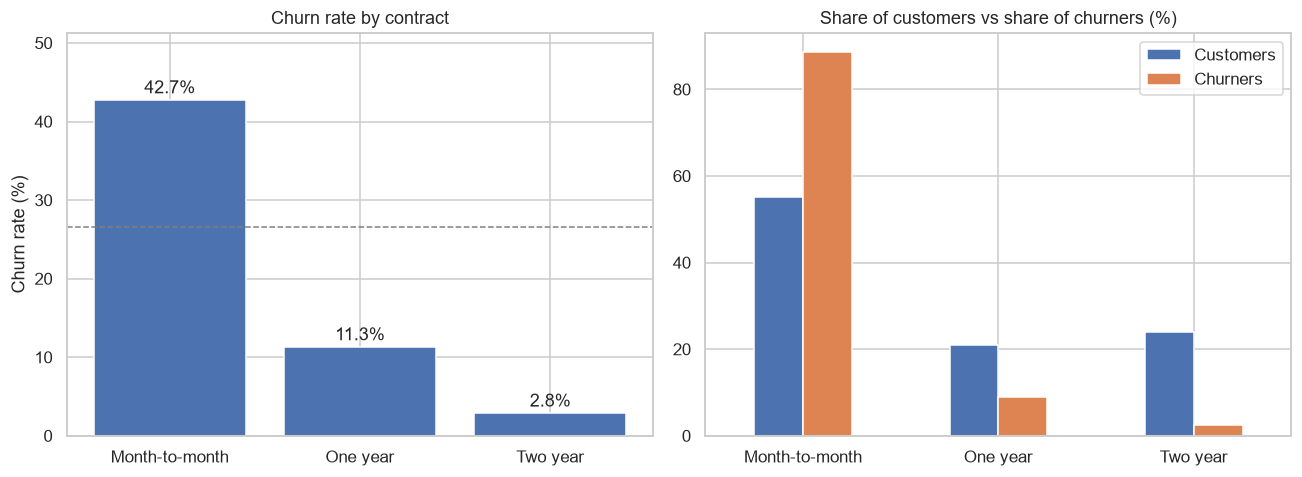

In [4]:
contract = churn_table(df, "contract")
share = pd.DataFrame({
    "Customers": 100 * contract["customers"] / contract["customers"].sum(),
    "Churners": 100 * contract["churned"] / contract["churned"].sum(),
})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
bar_rates(ax1, contract, "Churn rate by contract")
share.plot(kind="bar", ax=ax2, rot=0)
ax2.set_title("Share of customers vs share of churners (%)")
ax2.set_xlabel("")
plt.tight_layout()
save_fig("03_contract")
plt.show()

## Q4. Do churners pay more? (monthly and total charges)
Total charges mostly reflects tenure, so read it together with Q6.

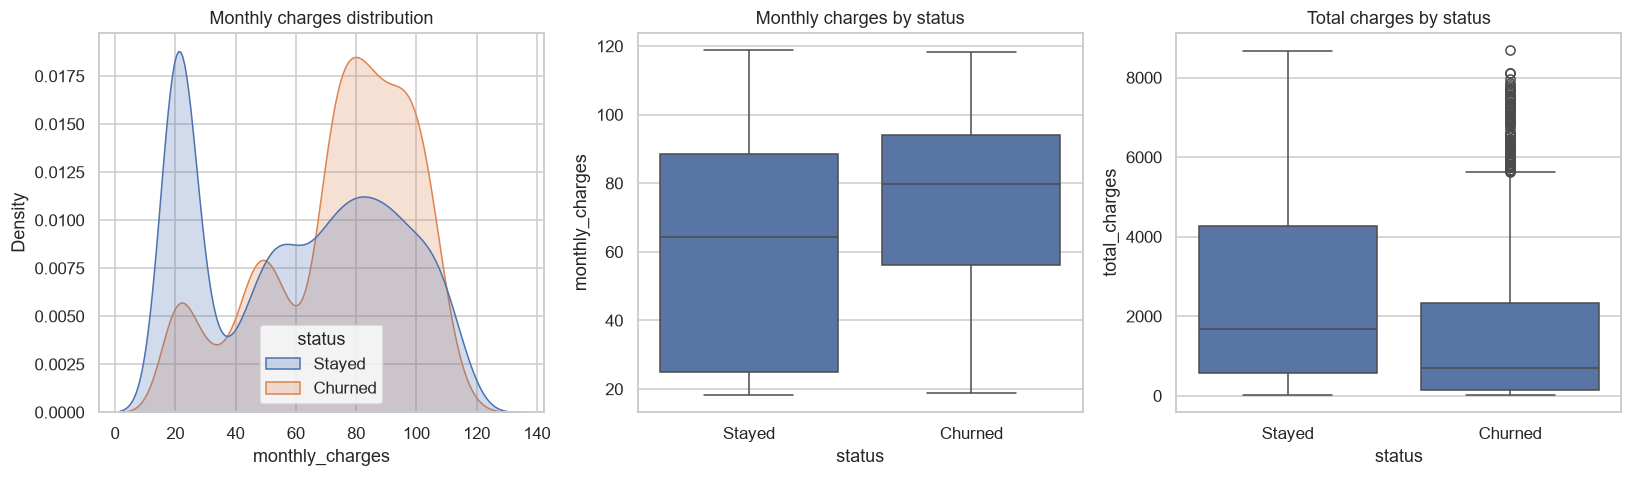

         monthly_charges  total_charges  tenure_months
status                                                
Churned            74.44        1531.80          17.98
Stayed             61.27        2555.34          37.57


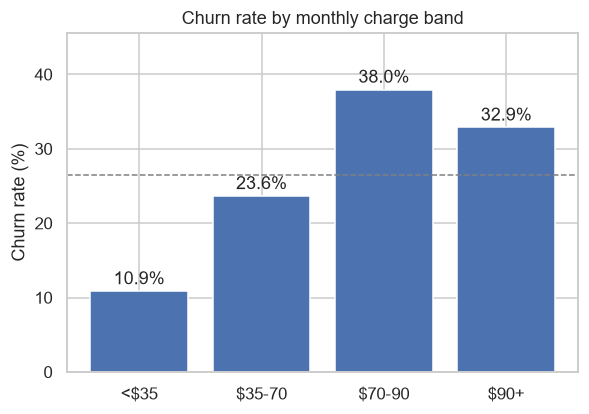

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
sns.kdeplot(data=df, x="monthly_charges", hue="status", common_norm=False, fill=True, ax=axes[0])
axes[0].set_title("Monthly charges distribution")
sns.boxplot(data=df, x="status", y="monthly_charges", ax=axes[1])
axes[1].set_title("Monthly charges by status")
sns.boxplot(data=df, x="status", y="total_charges", ax=axes[2])
axes[2].set_title("Total charges by status")
plt.tight_layout()
save_fig("04_charges")
plt.show()
print(df.groupby("status")[["monthly_charges", "total_charges", "tenure_months"]].mean().round(2))

fig, ax = plt.subplots(figsize=(6, 4))
bar_rates(ax, churn_table(df, "charge_band"), "Churn rate by monthly charge band")
save_fig("04b_charge_band")
plt.show()

## Q5. Which payment methods and billing choices are risky?

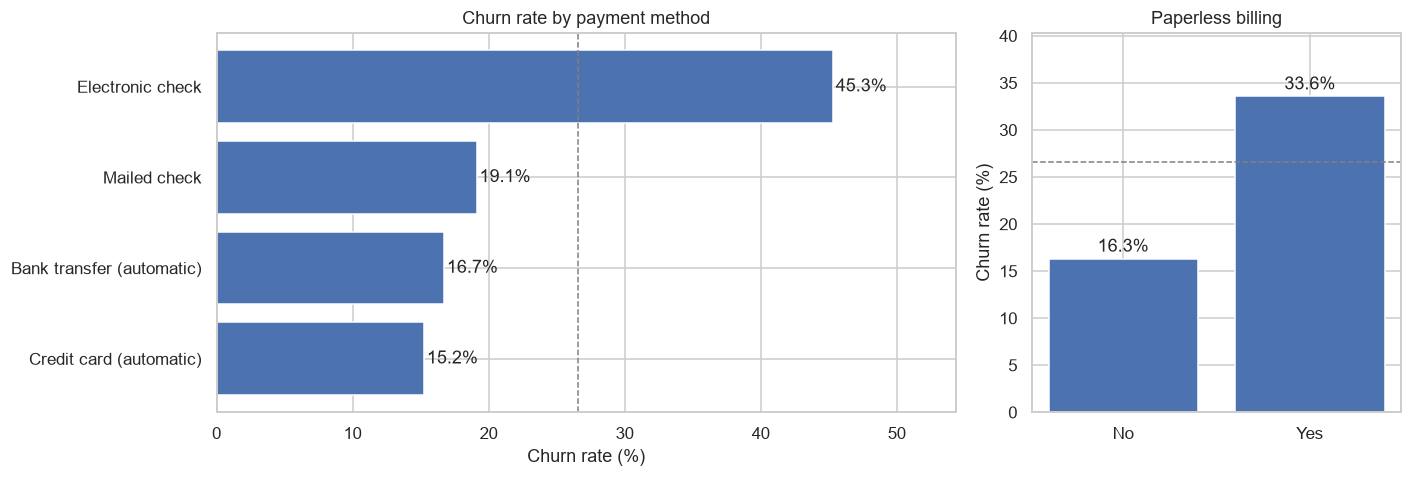

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2, 1]})
pay = churn_table(df, "payment_method").sort_values("churn_rate_pct")
bars = ax1.barh(pay.index, pay["churn_rate_pct"])
ax1.bar_label(bars, fmt="%.1f%%", padding=2)
ax1.axvline(OVERALL, ls="--", color="grey", lw=1)
ax1.set_title("Churn rate by payment method")
ax1.set_xlabel("Churn rate (%)")
ax1.set_xlim(0, pay["churn_rate_pct"].max() * 1.2)

paperless = df.assign(PaperlessBilling=df["paperless_billing"].map({1: "Yes", 0: "No"}))
bar_rates(ax2, churn_table(paperless, "PaperlessBilling"), "Paperless billing")
plt.tight_layout()
save_fig("05_payment")
plt.show()

## Q6. How does tenure shape churn? When do customers leave?
Right chart: churn rate for each tenure month (dots), smoothed with a 6-month rolling average (line).

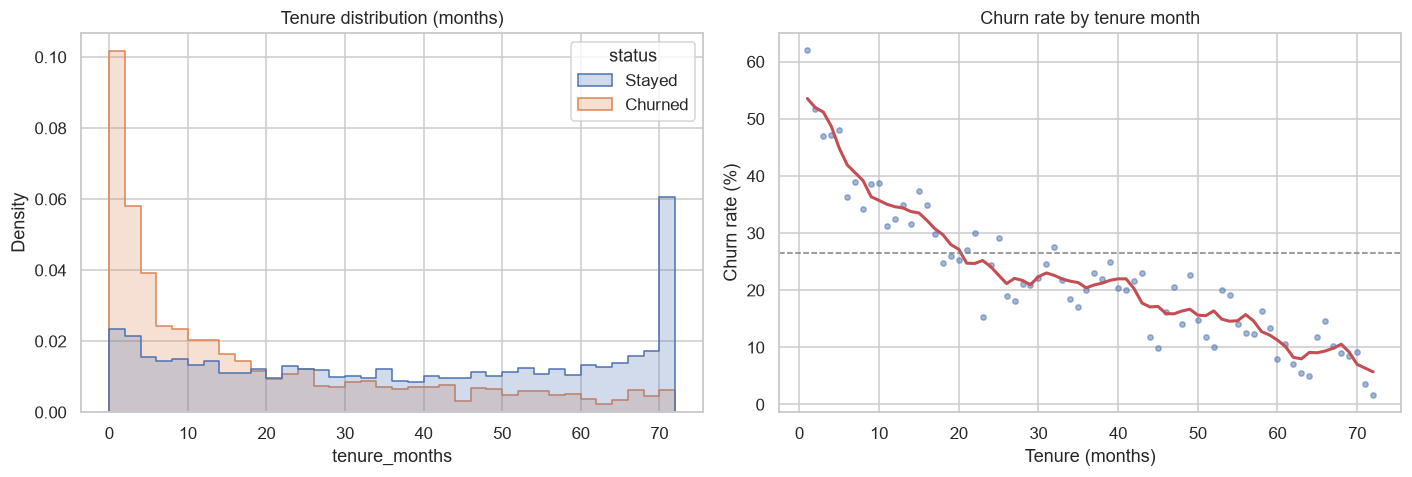

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=df, x="tenure_months", hue="status", bins=36, element="step",
             common_norm=False, stat="density", ax=ax1)
ax1.set_title("Tenure distribution (months)")

curve = df[df["tenure_months"] > 0].groupby("tenure_months")["churn"].mean() * 100
ax2.scatter(curve.index, curve.values, s=12, alpha=0.5)
ax2.plot(curve.index, curve.rolling(6, center=True, min_periods=1).mean(), color="#c44e52", lw=2)
ax2.axhline(OVERALL, ls="--", color="grey", lw=1)
ax2.set_title("Churn rate by tenure month")
ax2.set_xlabel("Tenure (months)")
ax2.set_ylabel("Churn rate (%)")
plt.tight_layout()
save_fig("06_tenure")
plt.show()

## Q7. Do support and security add-ons relate to churn?
Only customers with internet service are included, since others cannot buy add-ons.
This shows association, not cause: customers who buy add-ons may already be more engaged.

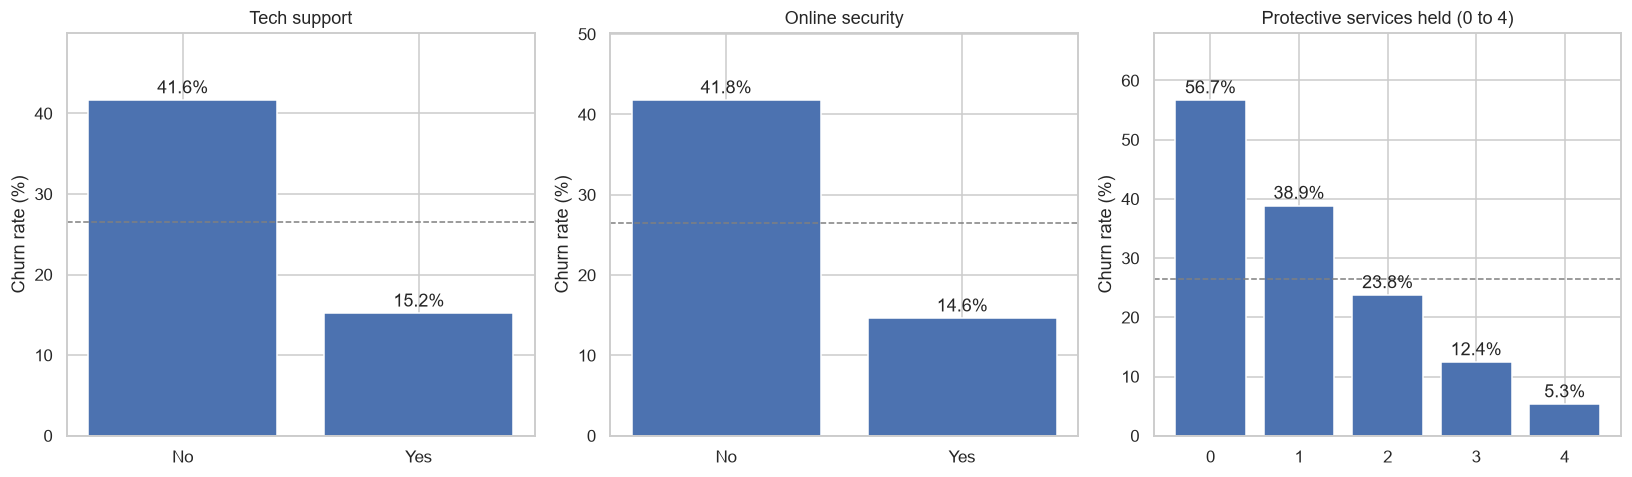

In [8]:
net = df[df["internet_service"] != "No"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
bar_rates(axes[0], churn_table(net, "tech_support"), "Tech support")
bar_rates(axes[1], churn_table(net, "online_security"), "Online security")
bar_rates(axes[2], churn_table(net, "protective_services"), "Protective services held (0 to 4)")
plt.tight_layout()
save_fig("07_support_security")
plt.show()

## Q8. What is correlated with what? Are any features redundant?
Correlation with churn shows signal strength. Correlation between two features
(for example tenure and total charges) warns us about redundancy.

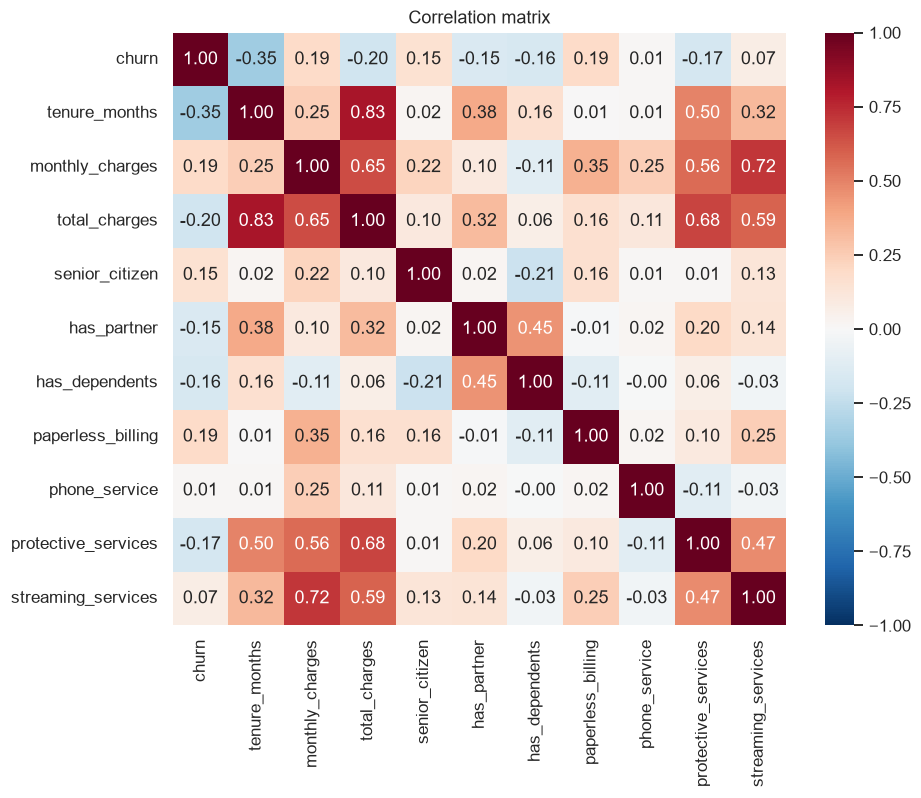

Correlation with churn:
tenure_months         -0.352
total_charges         -0.199
protective_services   -0.173
has_dependents        -0.164
has_partner           -0.150
phone_service          0.012
streaming_services     0.071
senior_citizen         0.151
paperless_billing      0.192
monthly_charges        0.193
Name: churn, dtype: float64

tenure vs total_charges: 0.826


In [9]:
corr_columns = [
    "churn", "tenure_months", "monthly_charges", "total_charges", "senior_citizen",
    "has_partner", "has_dependents", "paperless_billing", "phone_service",
    "protective_services", "streaming_services",
]
corr = df[corr_columns].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation matrix")
save_fig("08_correlation")
plt.show()

print("Correlation with churn:")
print(corr["churn"].drop("churn").sort_values().round(3))
print("\ntenure vs total_charges:", round(corr.loc["tenure_months", "total_charges"], 3))

## Q9. What are the key insights?

In [10]:
by_contract = churn_table(df, "contract")
by_internet = churn_table(df, "internet_service")
by_pay = churn_table(df, "payment_method")
by_tenure = churn_table(df, "tenure_band")
by_support = churn_table(net, "tech_support")

print("KEY INSIGHTS (all figures from this dataset, associations not causes)")
print(f"1. Overall churn: {OVERALL:.1f}% ({df['churn'].sum():,} of {len(df):,} customers)")
print(f"2. Highest-churn contract: {by_contract['churn_rate_pct'].idxmax()} "
      f"({by_contract['churn_rate_pct'].max():.1f}%)")
print(f"3. Highest-churn internet type: {by_internet['churn_rate_pct'].idxmax()} "
      f"({by_internet['churn_rate_pct'].max():.1f}%)")
print(f"4. Highest-churn payment method: {by_pay['churn_rate_pct'].idxmax()} "
      f"({by_pay['churn_rate_pct'].max():.1f}%)")
print(f"5. First-year churn: {by_tenure['churn_rate_pct'].iloc[0]:.1f}% "
      f"vs {by_tenure['churn_rate_pct'].iloc[-1]:.1f}% after 4 years")
print(f"6. Tech support (internet customers): "
      f"{by_support.loc['No', 'churn_rate_pct']:.1f}% without vs "
      f"{by_support.loc['Yes', 'churn_rate_pct']:.1f}% with")

KEY INSIGHTS (all figures from this dataset, associations not causes)
1. Overall churn: 26.5% (1,869 of 7,043 customers)
2. Highest-churn contract: Month-to-month (42.7%)
3. Highest-churn internet type: Fiber optic (41.9%)
4. Highest-churn payment method: Electronic check (45.3%)
5. First-year churn: 47.4% vs 9.5% after 4 years
6. Tech support (internet customers): 41.6% without vs 15.2% with
